# Theme Alpha Q7 Production Realism Practice

Q7 tests whether the shortlisted Theme Alpha candidates survive practical implementation assumptions:

- 10-trading-day versus monthly rebalancing;
- transaction costs;
- minimum rebalance thresholds;
- max single-period ETF trade limits.

In [ ]:
# Keep relative research paths stable after this notebook moved.
import os
from xquant.project import find_repo_root

REPO_ROOT = find_repo_root()
os.chdir(REPO_ROOT)


In [1]:
from pathlib import Path
import warnings
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

warnings.filterwarnings("ignore")
plt.rcParams["font.sans-serif"] = ["Arial Unicode MS", "SimHei", "STHeiti"]
plt.rcParams["axes.unicode_minus"] = False

OUTPUT_DIR = Path("outputs/theme-alpha-q7-production-realism")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_START = "2020-01-01"
END = (pd.Timestamp.today() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
TRADING_DAYS = 252
INITIAL_NAV = 100.0
REBALANCE_ANCHOR = "2020-01-02"

CSI300 = "510300.SS"
NASDAQ = "513100.SS"
NONFERROUS = "512400.SS"
CHIP = "159995.SZ"
COMM = "515880.SS"
GOLD = "518880.SS"
DIVIDEND = "510880.SS"
ENERGY = "159930.SZ"
BROKER = "512880.SS"
HK_TECH = "513180.SS"
HEALTHCARE = "512170.SS"

CORE_ASSETS = (CSI300, NASDAQ, GOLD)
EXPANDED_THEME = (NASDAQ, NONFERROUS, CHIP, COMM, GOLD, DIVIDEND, ENERGY, BROKER, HK_TECH, HEALTHCARE)
ALL_SYMBOLS = tuple(dict.fromkeys(CORE_ASSETS + EXPANDED_THEME))
SYMBOL_NAMES = {
    CSI300: "沪深300ETF",
    NASDAQ: "纳指100ETF",
    NONFERROUS: "有色金属ETF",
    CHIP: "芯片ETF",
    COMM: "通信ETF",
    GOLD: "黄金ETF",
    DIVIDEND: "红利ETF",
    ENERGY: "能源ETF",
    BROKER: "证券ETF",
    HK_TECH: "恒生科技ETF",
    HEALTHCARE: "医疗ETF",
}

MA_WINDOW = 60
MOM_WINDOW = 63
VOL_WINDOW = 60
TOP_N = 3
RP_VOL_WINDOW = 20
CAP = 0.50

CANDIDATES = {
    "Base_Core80_LVT20": {"defense": None, "destination": None},
    "Def200_Cash": {"defense": 200, "destination": "cash"},
    "Def120_Cash": {"defense": 120, "destination": "cash"},
    "Def210_Gold": {"defense": 210, "destination": "gold"},
}
FREQUENCIES = ("10D", "M")
COST_BPS_GRID = (0, 10, 20, 30)
THRESHOLDS = (0.00, 0.02, 0.05)
MAX_TRADE_LIMITS = (None, 0.10, 0.15, 0.20)

WINDOWS = {
    "2021_to_date": ("2021-01-01", None),
    "2021_2022_bear": ("2021-02-18", "2022-10-31"),
    "2022_full": ("2022-01-01", "2022-12-31"),
    "2025_to_date": ("2025-01-01", None),
    "2026_ytd": ("2026-01-01", None),
}

print(f"Output dir: {OUTPUT_DIR}")
print(f"End date request: {END}")

Output dir: outputs/theme-alpha-q7-production-realism
End date request: 2026-06-24


## Data

In [2]:
def download_close(symbol):
    df = yf.download(symbol, start=DATA_START, end=END, auto_adjust=True, progress=False, threads=False)
    if df.empty:
        raise ValueError(f"No data for {symbol}")
    if isinstance(df.columns, pd.MultiIndex):
        df = df.droplevel(1, axis=1)
    col = "Close" if "Close" in df.columns else "Adj Close"
    return df[col].rename(symbol)

raw_close = [download_close(symbol) for symbol in ALL_SYMBOLS]
close_raw = pd.concat(raw_close, axis=1).sort_index()
availability = pd.DataFrame([
    {
        "symbol": sym,
        "name": SYMBOL_NAMES[sym],
        "first_date": close_raw[sym].dropna().index.min().date(),
        "last_date": close_raw[sym].dropna().index.max().date(),
        "rows": int(close_raw[sym].dropna().shape[0]),
    }
    for sym in ALL_SYMBOLS
])
availability.to_csv(OUTPUT_DIR / "data_availability.csv", index=False, encoding="utf-8-sig")
display(availability)

close = close_raw.ffill()
returns = close.pct_change(fill_method=None)

,symbol,name,first_date,last_date,rows
0,510300.SS,沪深300ETF,2020-01-02,2026-06-23,1565
1,513100.SS,纳指100ETF,2020-01-02,2026-06-23,1566
2,518880.SS,黄金ETF,2020-01-02,2026-06-23,1565
3,512400.SS,有色金属ETF,2020-01-02,2026-06-23,1565
4,159995.SZ,芯片ETF,2020-01-20,2026-06-23,1547
5,515880.SS,通信ETF,2020-01-02,2026-06-23,1565
6,510880.SS,红利ETF,2020-01-02,2026-06-23,1565
7,159930.SZ,能源ETF,2020-01-02,2026-06-23,1543
8,512880.SS,证券ETF,2020-01-02,2026-06-23,1565
9,513180.SS,恒生科技ETF,2021-05-18,2026-06-23,1233


## Strategy and Execution Helpers

In [3]:
def normalize_weights(weights, universe):
    clean = {sym: float(max(0.0, weights.get(sym, 0.0))) for sym in universe}
    total = sum(clean.values())
    if total > 1.0 + 1e-12:
        clean = {sym: val / total for sym, val in clean.items()}
        total = 1.0
    clean["CASH"] = max(0.0, 1.0 - total)
    return clean


def apply_cap(weights, universe, cap=None):
    if cap is None:
        return normalize_weights(weights, universe)
    s = pd.Series({sym: max(0.0, weights.get(sym, 0.0)) for sym in universe}, dtype=float)
    total = s.sum()
    if total <= 0:
        return normalize_weights({}, universe)
    s = s / total
    cap = float(cap)
    for _ in range(30):
        over = s > cap + 1e-12
        if not over.any():
            break
        excess = (s[over] - cap).sum()
        s[over] = cap
        under = s < cap - 1e-12
        capacity = (cap - s[under]).clip(lower=0.0)
        if excess <= 1e-12 or capacity.sum() <= 1e-12:
            break
        base = s[under].clip(lower=0.0)
        add = excess * (base / base.sum() if base.sum() > 1e-12 else capacity / capacity.sum())
        add = np.minimum(add, capacity)
        s.loc[add.index] += add
    return normalize_weights(s.to_dict(), universe)


def rebalance_dates(index, frequency):
    idx = pd.DatetimeIndex(index)
    if frequency == "10D":
        start = idx.searchsorted(pd.Timestamp(REBALANCE_ANCHOR))
        return set(pd.DatetimeIndex(idx[start::10]))
    if frequency == "M":
        monthly = pd.Series(idx, index=idx).resample("ME").last().dropna()
        return set(pd.DatetimeIndex(monthly.values))
    raise ValueError(frequency)


def enough_history(sym, loc, window):
    if loc < window:
        return False
    hist = close[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def enough_return_history(sym, loc, window):
    if loc < window:
        return False
    hist = returns[sym].iloc[loc - window + 1:loc + 1]
    return hist.notna().all()


def risk_parity_weight(date, eligible, universe, cap=None):
    loc = close.index.get_loc(date)
    eligible = [sym for sym in eligible if sym in universe and enough_return_history(sym, loc, RP_VOL_WINDOW)]
    if not eligible:
        return normalize_weights({}, universe)
    hist = returns.iloc[loc - RP_VOL_WINDOW + 1:loc + 1][eligible]
    vols = hist.std(ddof=1).replace(0, np.nan).dropna()
    vols = vols[vols > 0]
    if vols.empty:
        return normalize_weights({}, universe)
    inv = 1.0 / vols
    raw = (inv / inv.sum()).to_dict()
    return apply_cap(raw, universe, cap)


def low_vol_trend_selector(universe):
    def select(date):
        loc = close.index.get_loc(date)
        warmup = max(MA_WINDOW, MOM_WINDOW, VOL_WINDOW)
        if loc < warmup:
            return []
        valid = []
        for sym in universe:
            if not enough_history(sym, loc, max(MA_WINDOW, MOM_WINDOW + 1)):
                continue
            if not enough_return_history(sym, loc, VOL_WINDOW):
                continue
            valid.append(sym)
        if not valid:
            return []
        price = close.iloc[loc][valid]
        ma = close.iloc[loc - MA_WINDOW + 1:loc + 1][valid].mean()
        mom = price / close.iloc[loc - MOM_WINDOW][valid] - 1.0
        vols = returns.iloc[loc - VOL_WINDOW + 1:loc + 1][valid].std(ddof=1)
        eligible = price.index[(price > ma) & (mom > 0)].tolist()
        if not eligible:
            return []
        return vols[eligible].sort_values().head(TOP_N).index.tolist()
    return select


def all_assets(universe):
    return lambda _date: list(universe)


def build_weights(universe, selector, allocator, frequency):
    rdates = rebalance_dates(close.index, frequency)
    rows = []
    last = normalize_weights({}, universe)
    for date in close.index:
        if date in rdates:
            last = allocator(date, selector(date))
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    for col in list(universe) + ["CASH"]:
        if col not in out.columns:
            out[col] = 0.0
    return out[list(universe) + ["CASH"]]


def defend_core_weights(weights, ma_window, destination, frequency):
    rdates = rebalance_dates(close.index, frequency)
    rows = []
    last = normalize_weights({}, CORE_ASSETS)
    for date in close.index:
        if date in rdates:
            loc = close.index.get_loc(date)
            base = weights.loc[date, list(CORE_ASSETS) + ["CASH"]].copy()
            for sym in (CSI300, NASDAQ):
                risk_on = enough_history(sym, loc, ma_window) and close.at[date, sym] > close[sym].iloc[loc - ma_window + 1:loc + 1].mean()
                if not risk_on:
                    moved = base[sym]
                    base[sym] = 0.0
                    if destination == "cash":
                        base["CASH"] += moved
                    elif destination == "gold":
                        base[GOLD] += moved
                    else:
                        raise ValueError(destination)
            last = normalize_weights(base.to_dict(), CORE_ASSETS)
        rows.append(last)
    out = pd.DataFrame(rows, index=close.index).fillna(0.0)
    return out[list(CORE_ASSETS) + ["CASH"]]


def expand_weights(weights, all_assets):
    out = pd.DataFrame(0.0, index=weights.index, columns=list(all_assets) + ["CASH"])
    for col in weights.columns:
        if col in out.columns:
            out[col] = weights[col]
    return out


def combine_weights(sleeves):
    out = pd.DataFrame(0.0, index=close.index, columns=list(ALL_SYMBOLS) + ["CASH"])
    for allocation, weights in sleeves:
        ew = expand_weights(weights, ALL_SYMBOLS)
        out += allocation * ew.reindex(close.index).ffill().fillna(0.0)
    total = out[list(ALL_SYMBOLS)].sum(axis=1) + out["CASH"]
    return out.div(total.replace(0, np.nan), axis=0).fillna(0.0)


def apply_execution_constraints(target_weights, threshold=0.0, max_trade=None):
    cols = list(ALL_SYMBOLS) + ["CASH"]
    target = target_weights[cols].copy().fillna(0.0)
    executed_rows = []
    current = pd.Series(0.0, index=cols)
    current["CASH"] = 1.0
    last_target = None
    for date, row in target.iterrows():
        changed = last_target is None or (row - last_target).abs().sum() > 1e-10
        if changed:
            desired = row.copy()
            turnover = 0.5 * (desired - current).abs().sum()
            if turnover >= threshold - 1e-12:
                if max_trade is None:
                    current = desired.copy()
                else:
                    asset_cols = list(ALL_SYMBOLS)
                    delta = (desired[asset_cols] - current[asset_cols]).clip(lower=-max_trade, upper=max_trade)
                    new_assets = (current[asset_cols] + delta).clip(lower=0.0)
                    asset_sum = new_assets.sum()
                    if asset_sum > 1.0:
                        new_assets = new_assets / asset_sum
                        cash = 0.0
                    else:
                        cash = 1.0 - asset_sum
                    current = pd.concat([new_assets, pd.Series({"CASH": cash})]).reindex(cols).fillna(0.0)
            last_target = row.copy()
        executed_rows.append(current.to_dict())
    return pd.DataFrame(executed_rows, index=target.index, columns=cols)


def turnover_from_weights(signal_weights):
    actual = signal_weights[list(ALL_SYMBOLS) + ["CASH"]].shift(1).fillna(0.0)
    return 0.5 * actual.diff().abs().sum(axis=1).fillna(actual.abs().sum(axis=1))


def backtest(name, signal_weights, cost_bps=0.0):
    asset_weights = signal_weights[list(ALL_SYMBOLS)].shift(1).fillna(0.0)
    gross = (asset_weights * returns[list(ALL_SYMBOLS)]).sum(axis=1, min_count=1).fillna(0.0)
    turnover = turnover_from_weights(signal_weights)
    net = gross - turnover * (cost_bps / 10000.0)
    nav = (1.0 + net).cumprod() * INITIAL_NAV
    return {"name": name, "weights": signal_weights, "returns": net, "gross_returns": gross, "turnover": turnover, "nav": nav.rename(name), "cost_bps": cost_bps}

## Build Target Weights

In [4]:
targets = {}
for freq in FREQUENCIES:
    core = build_weights(CORE_ASSETS, all_assets(CORE_ASSETS), lambda d, e: risk_parity_weight(d, e, CORE_ASSETS, None), freq)
    lvt = build_weights(EXPANDED_THEME, low_vol_trend_selector(EXPANDED_THEME), lambda d, e: risk_parity_weight(d, e, EXPANDED_THEME, CAP), freq)
    for candidate, cfg in CANDIDATES.items():
        if cfg["defense"] is None:
            core_used = core
        else:
            core_used = defend_core_weights(core, cfg["defense"], cfg["destination"], freq)
        targets[(candidate, freq)] = combine_weights([(0.80, core_used), (0.20, lvt)])

latest_rows = []
for (candidate, freq), weights in targets.items():
    latest_rows.append({"candidate": candidate, "frequency": freq, **{SYMBOL_NAMES.get(c, c): weights[c].iloc[-1] for c in ALL_SYMBOLS}, "现金": weights["CASH"].iloc[-1]})
latest_targets = pd.DataFrame(latest_rows)
latest_targets.to_csv(OUTPUT_DIR / "latest_target_weights.csv", index=False, encoding="utf-8-sig")
display(latest_targets.round(4))

,candidate,frequency,沪深300ETF,纳指100ETF,黄金ETF,有色金属ETF,芯片ETF,通信ETF,红利ETF,能源ETF,证券ETF,恒生科技ETF,医疗ETF,现金
0,Base_Core80_LVT20,10D,0.3676,0.261,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0000,0.0,0.0,0.0
1,Def200_Cash,10D,0.3676,0.261,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0000,0.0,0.0,0.0
2,Def120_Cash,10D,0.3676,0.261,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0000,0.0,0.0,0.0
3,Def210_Gold,10D,0.3676,0.261,0.2573,0.0,0.0566,0.0575,0.0,0.0,0.0000,0.0,0.0,0.0
4,Base_Core80_LVT20,M,0.3400,0.264,0.2681,0.0,0.0000,0.0491,0.0,0.0,0.0788,0.0,0.0,0.0
5,Def200_Cash,M,0.3400,0.264,0.2681,0.0,0.0000,0.0491,0.0,0.0,0.0788,0.0,0.0,0.0
6,Def120_Cash,M,0.3400,0.264,0.2681,0.0,0.0000,0.0491,0.0,0.0,0.0788,0.0,0.0,0.0
7,Def210_Gold,M,0.3400,0.264,0.2681,0.0,0.0000,0.0491,0.0,0.0,0.0788,0.0,0.0,0.0


## Build Executed Portfolios

In [5]:
portfolio_records = []
portfolios = {}
for candidate, freq, cost_bps, threshold, max_trade in product(CANDIDATES.keys(), FREQUENCIES, COST_BPS_GRID, THRESHOLDS, MAX_TRADE_LIMITS):
    target = targets[(candidate, freq)]
    executed = apply_execution_constraints(target, threshold=threshold, max_trade=max_trade)
    max_trade_label = "unlimited" if max_trade is None else f"max{int(max_trade * 100)}"
    threshold_label = f"thr{int(threshold * 100)}"
    name = f"{candidate}_{freq}_cost{cost_bps}_{threshold_label}_{max_trade_label}"
    port = backtest(name, executed, cost_bps=cost_bps)
    portfolios[name] = port
    portfolio_records.append({
        "name": name,
        "candidate": candidate,
        "frequency": freq,
        "cost_bps": cost_bps,
        "threshold": threshold,
        "max_trade": np.nan if max_trade is None else max_trade,
    })
portfolio_index = pd.DataFrame(portfolio_records)
portfolio_index.to_csv(OUTPUT_DIR / "portfolio_index.csv", index=False, encoding="utf-8-sig")
print(f"Built {len(portfolios)} executed portfolios")

Built 384 executed portfolios


## Metrics

In [6]:
def period_slice(series_or_df, start, end):
    obj = series_or_df.loc[pd.Timestamp(start):]
    if end is not None:
        obj = obj.loc[:pd.Timestamp(end)]
    return obj.dropna(how="all") if isinstance(obj, pd.DataFrame) else obj.dropna()


def nav_from_returns(r):
    return (1.0 + r).cumprod() * INITIAL_NAV


def drawdown_series(nav):
    nav = nav.dropna()
    if nav.empty:
        return nav
    initial_peak = pd.Series([INITIAL_NAV], index=[nav.index[0] - pd.Timedelta(nanoseconds=1)])
    peak = pd.concat([initial_peak, nav]).cummax().iloc[1:]
    return nav / peak - 1.0


def recovery_summary(nav):
    nav = nav.dropna()
    if nav.empty:
        return {"水下时间占比": np.nan, "平均水下": np.nan, "最长水下天数": np.nan, "超过-10%天数": np.nan, "超过-20%天数": np.nan, "未修复回撤": np.nan}
    dd = drawdown_series(nav)
    underwater = dd < -1e-12
    longest = cur = 0
    for val in underwater.astype(bool):
        cur = cur + 1 if val else 0
        longest = max(longest, cur)
    return {
        "水下时间占比": float(underwater.mean()),
        "平均水下": float(dd[underwater].mean()) if underwater.any() else 0.0,
        "最长水下天数": int(longest),
        "超过-10%天数": int((dd <= -0.10).sum()),
        "超过-20%天数": int((dd <= -0.20).sum()),
        "未修复回撤": float(dd.iloc[-1]) if underwater.iloc[-1] else 0.0,
    }


def metrics_row(name, port, start, end):
    r = period_slice(port["returns"], start, end)
    w = period_slice(port["weights"], start, end)
    t = period_slice(port["turnover"], start, end)
    nav = nav_from_returns(r)
    total = float((1.0 + r).prod() - 1.0)
    years = max(len(r) / TRADING_DAYS, 1e-12)
    ann = (1.0 + total) ** (1.0 / years) - 1.0
    vol = r.std(ddof=1) * np.sqrt(TRADING_DAYS)
    sharpe = ann / vol if vol and vol > 0 else np.nan
    downside = r[r < 0].std(ddof=1) * np.sqrt(TRADING_DAYS)
    sortino = ann / downside if downside and downside > 0 else np.nan
    dd = drawdown_series(nav)
    mdd = float(dd.min()) if len(dd) else np.nan
    calmar = ann / abs(mdd) if mdd < 0 else np.nan
    monthly = r.resample("ME").apply(lambda x: (1.0 + x).prod() - 1.0)
    gains = monthly[monthly > 0]
    losses = monthly[monthly < 0]
    out = {
        "name": name,
        "累计收益": total,
        "年化收益": ann,
        "年化波动": vol,
        "最大回撤": mdd,
        "夏普": sharpe,
        "索提诺": sortino,
        "卡玛": calmar,
        "月胜率": (monthly > 0).mean(),
        "平均盈利月": gains.mean() if len(gains) else 0.0,
        "平均亏损月": losses.mean() if len(losses) else 0.0,
        "最好月份": monthly.max() if len(monthly) else np.nan,
        "最差月份": monthly.min() if len(monthly) else np.nan,
        "盈利因子": gains.sum() / abs(losses.sum()) if abs(losses.sum()) > 1e-12 else np.nan,
        "年化换手": t.sum() / years,
        "总换手": t.sum(),
        "平均现金": w["CASH"].mean(),
        "平均最大单资产权重": w[list(ALL_SYMBOLS)].max(axis=1).mean(),
        "当前最大单资产权重": w[list(ALL_SYMBOLS)].iloc[-1].max(),
    }
    out.update(recovery_summary(nav))
    return out

## Evaluate All Variants

In [7]:
summary_tables = {}
all_summary_rows = []
for window_name, (start, end) in WINDOWS.items():
    rows = []
    for rec in portfolio_records:
        name = rec["name"]
        row = metrics_row(name, portfolios[name], start, end)
        row.update(rec)
        rows.append(row)
        all_summary_rows.append({"window": window_name, **row})
    summary = pd.DataFrame(rows)
    summary.to_csv(OUTPUT_DIR / f"summary_all_variants_{window_name}.csv", index=False, encoding="utf-8-sig")
    summary_tables[window_name] = summary
    print(f"{window_name}: {summary.shape}")
all_summary = pd.DataFrame(all_summary_rows)
all_summary.to_csv(OUTPUT_DIR / "summary_all_windows.csv", index=False, encoding="utf-8-sig")

2021_to_date: (384, 30)


2021_2022_bear: (384, 30)


2022_full: (384, 30)


2025_to_date: (384, 30)


2026_ytd: (384, 30)


## Focused Comparisons

In [8]:
def subset(window, **filters):
    df = summary_tables[window].copy()
    for k, v in filters.items():
        if isinstance(v, (list, tuple, set)):
            df = df[df[k].isin(v)]
        else:
            df = df[df[k] == v]
    return df

def with_window(df, window):
    out = df.copy()
    out.insert(0, "window", window)
    return out

# Cost sensitivity: base execution, 10D, no threshold, unlimited trades.
cost_rows = []
for window in WINDOWS:
    df = subset(window, frequency="10D", threshold=0.0)
    df = df[df["max_trade"].isna()]
    cost_rows.append(with_window(df, window))
cost_sensitivity = pd.concat(cost_rows, ignore_index=True)
cost_sensitivity.to_csv(OUTPUT_DIR / "cost_sensitivity.csv", index=False, encoding="utf-8-sig")

# Rebalance frequency comparison: 20bps, no threshold, unlimited trades.
freq_rows = []
for window in WINDOWS:
    df = subset(window, cost_bps=20, threshold=0.0)
    df = df[df["max_trade"].isna()]
    freq_rows.append(with_window(df, window))
rebalance_frequency_comparison = pd.concat(freq_rows, ignore_index=True)
rebalance_frequency_comparison.to_csv(OUTPUT_DIR / "rebalance_frequency_comparison.csv", index=False, encoding="utf-8-sig")

# Execution constraints: 10D, 20bps, all thresholds and max trade settings.
exec_rows = []
for window in WINDOWS:
    df = subset(window, frequency="10D", cost_bps=20)
    exec_rows.append(with_window(df, window))
execution_constraint_comparison = pd.concat(exec_rows, ignore_index=True)
execution_constraint_comparison.to_csv(OUTPUT_DIR / "execution_constraint_comparison.csv", index=False, encoding="utf-8-sig")

# Robustness scorecard: practical default stress setting.
# 20bps, 2% threshold, 15% max single ETF trade.
robust_rows = []
for window in WINDOWS:
    df = subset(window, cost_bps=20, threshold=0.02, max_trade=0.15)
    robust_rows.append(with_window(df, window))
robustness_scorecard = pd.concat(robust_rows, ignore_index=True)
robustness_scorecard.to_csv(OUTPUT_DIR / "robustness_scorecard.csv", index=False, encoding="utf-8-sig")

display(robustness_scorecard[["window", "candidate", "frequency", "累计收益", "最大回撤", "夏普", "卡玛", "超过-10%天数", "年化换手", "平均现金"]].round(4))

,window,candidate,frequency,累计收益,最大回撤,夏普,卡玛,超过-10%天数,年化换手,平均现金
0,2021_to_date,Base_Core80_LVT20,10D,1.1924,-0.1186,1.3520,1.3599,29,2.8502,0.0008
1,2021_to_date,Base_Core80_LVT20,M,1.0557,-0.1692,1.2174,0.8694,225,2.0727,0.0082
2,2021_to_date,Def200_Cash,10D,1.0743,-0.1144,1.4296,1.3037,1,3.4724,0.1607
3,2021_to_date,Def200_Cash,M,1.0153,-0.1061,1.3313,1.3461,2,2.4595,0.1507
4,2021_to_date,Def120_Cash,10D,0.9276,-0.0985,1.3217,1.3518,0,4.0350,0.1691
5,2021_to_date,Def120_Cash,M,0.7790,-0.1299,1.1516,0.8930,188,2.9423,0.1874
6,2021_to_date,Def210_Gold,10D,1.3693,-0.1177,1.5189,1.5171,1,3.1134,0.0083
7,2021_to_date,Def210_Gold,M,1.1750,-0.1061,1.3582,1.5038,2,2.1238,0.0147
8,2021_2022_bear,Base_Core80_LVT20,10D,-0.1113,-0.1186,-0.6426,-0.5859,25,2.8931,0.0002
9,2021_2022_bear,Base_Core80_LVT20,M,-0.1692,-0.1692,-0.9813,-0.6321,148,2.1033,0.0117


## Charts for Practical Defaults

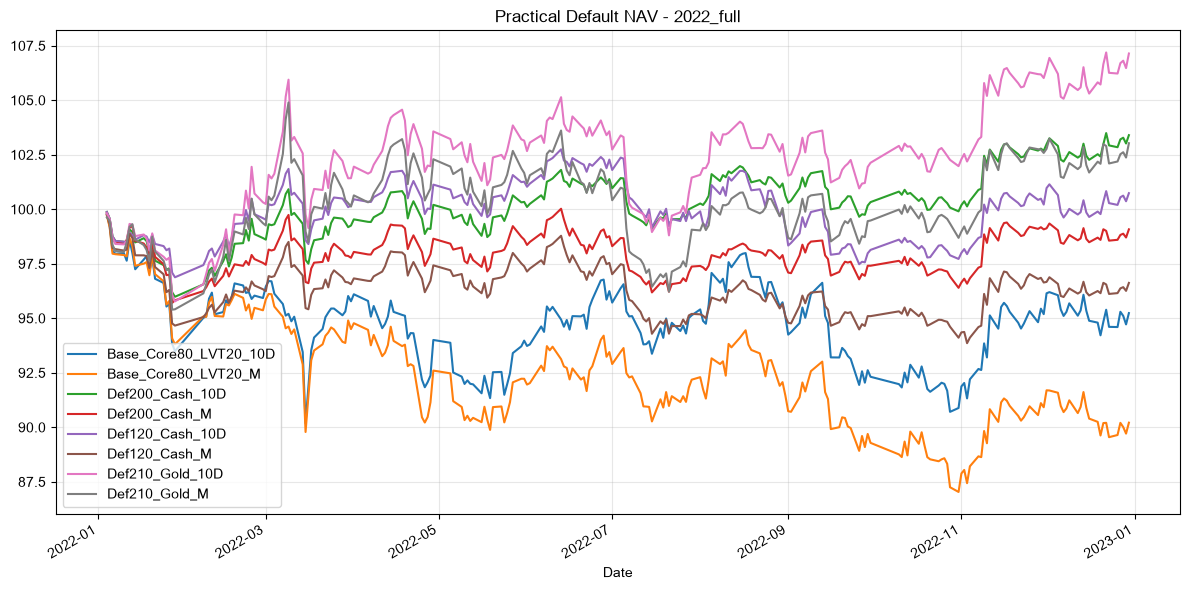

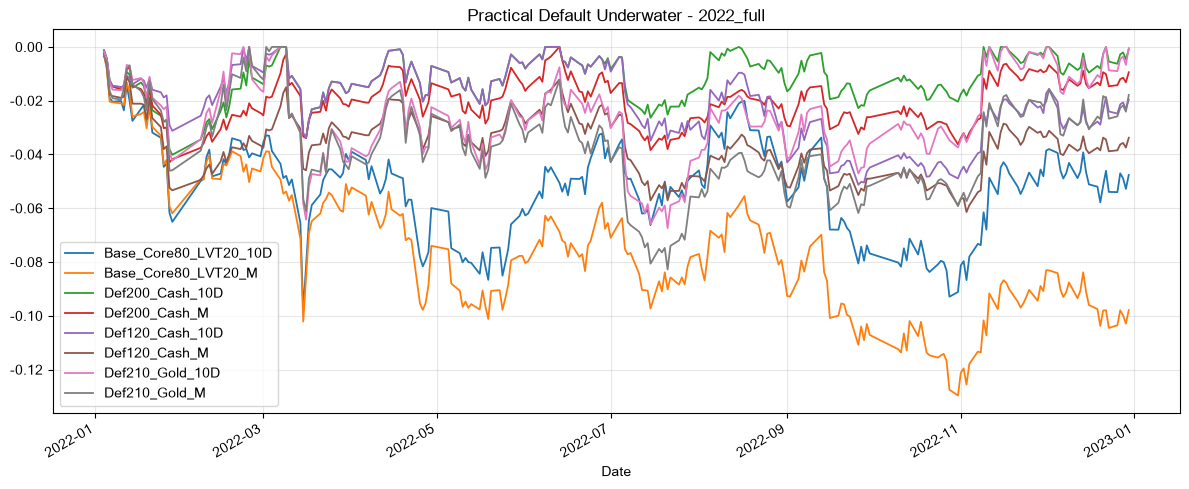

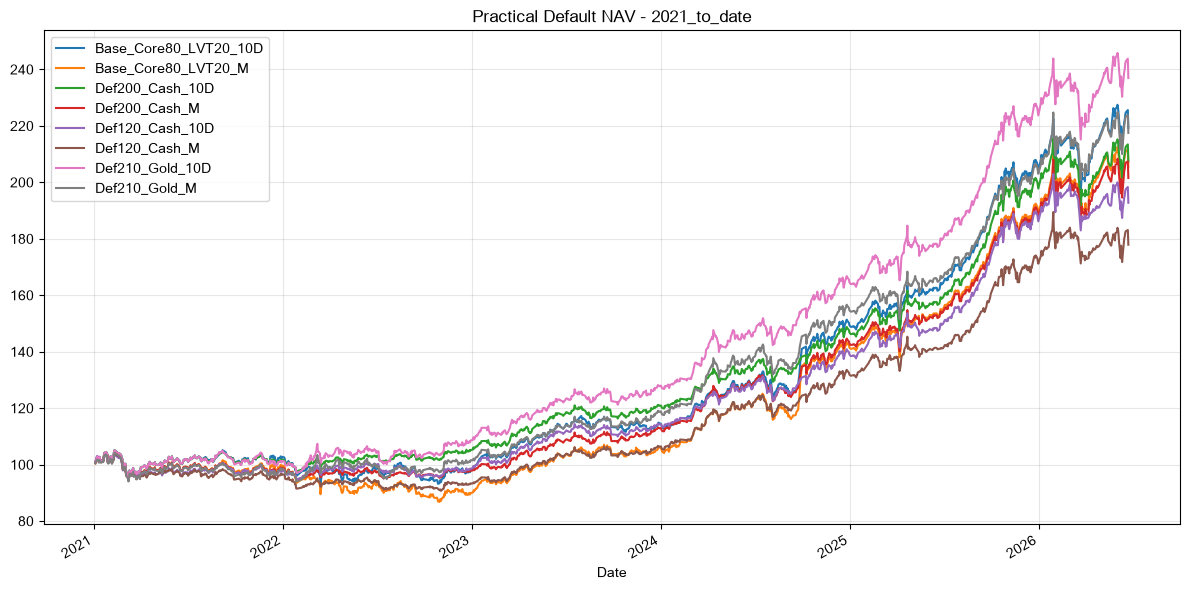

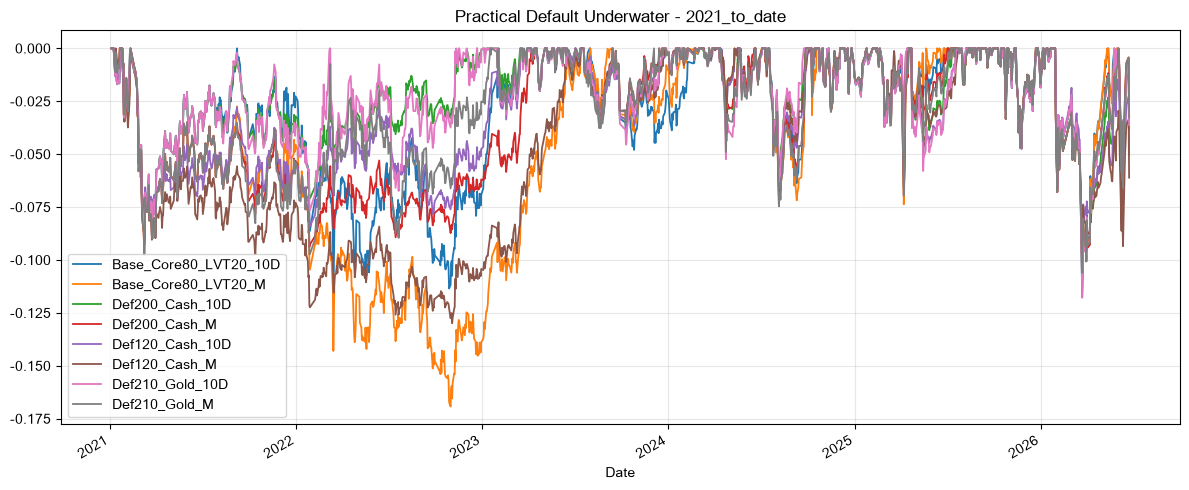

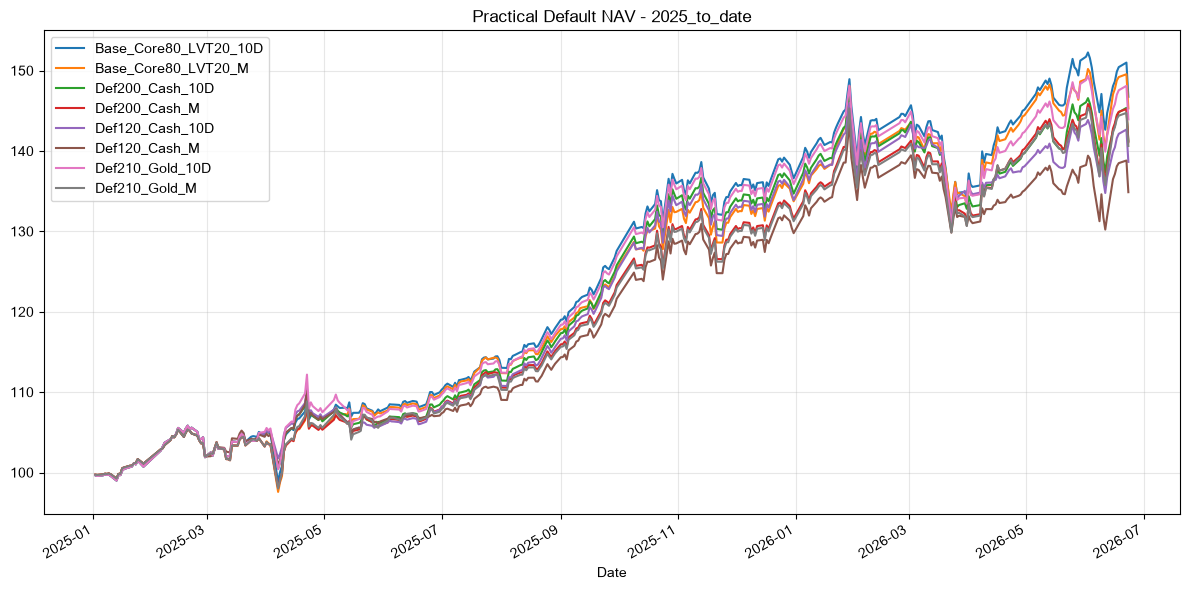

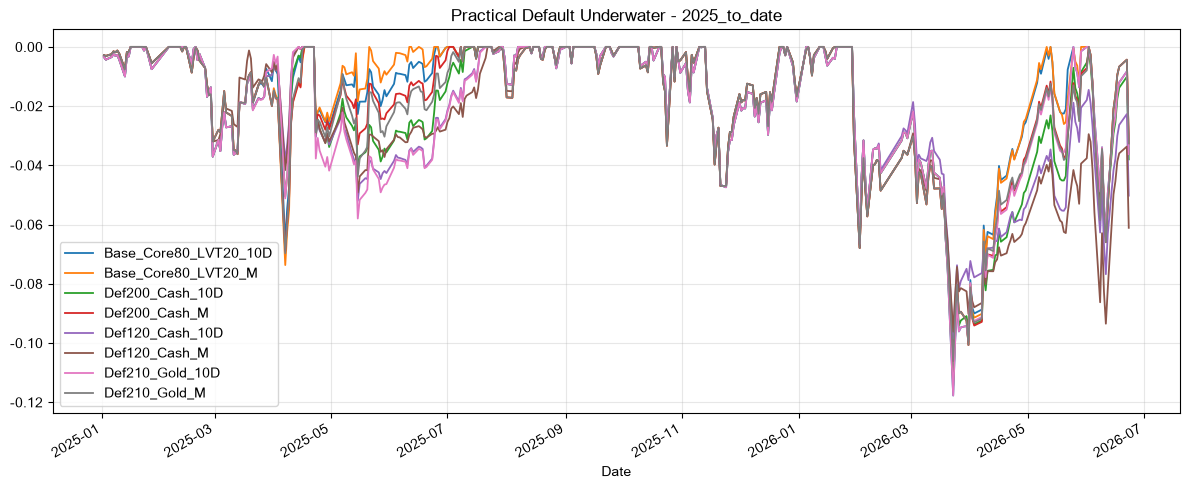

In [9]:
def nav_for(name, start, end):
    r = period_slice(portfolios[name]["returns"], start, end)
    return nav_from_returns(r)

selected_setting = {"cost_bps": 20, "threshold": 0.02, "max_trade": 0.15}
for window_name, (start, end) in {k: WINDOWS[k] for k in ["2022_full", "2021_to_date", "2025_to_date"]}.items():
    names = []
    labels = []
    for candidate in CANDIDATES:
        for freq in FREQUENCIES:
            match = portfolio_index[
                (portfolio_index["candidate"] == candidate)
                & (portfolio_index["frequency"] == freq)
                & (portfolio_index["cost_bps"] == selected_setting["cost_bps"])
                & (portfolio_index["threshold"] == selected_setting["threshold"])
                & (portfolio_index["max_trade"].fillna(-1) == selected_setting["max_trade"])
            ]
            if len(match):
                names.append(match.iloc[0]["name"])
                labels.append(f"{candidate}_{freq}")
    nav_df = pd.DataFrame({label: nav_for(name, start, end) for label, name in zip(labels, names)})
    uw_df = nav_df.apply(drawdown_series)
    nav_df.to_csv(OUTPUT_DIR / f"nav_practical_default_{window_name}.csv", encoding="utf-8-sig")
    uw_df.to_csv(OUTPUT_DIR / f"underwater_practical_default_{window_name}.csv", encoding="utf-8-sig")
    fig, ax = plt.subplots(figsize=(12, 6))
    nav_df.plot(ax=ax, linewidth=1.5)
    ax.set_title(f"Practical Default NAV - {window_name}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"nav_practical_default_{window_name}.png", dpi=160)
    plt.show()

    fig, ax = plt.subplots(figsize=(12, 5))
    uw_df.plot(ax=ax, linewidth=1.3)
    ax.set_title(f"Practical Default Underwater - {window_name}")
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"underwater_practical_default_{window_name}.png", dpi=160)
    plt.show()

## Research Summary

In [10]:
summary_focus = robustness_scorecard[["window", "candidate", "frequency", "cost_bps", "threshold", "max_trade", "累计收益", "最大回撤", "夏普", "卡玛", "超过-10%天数", "年化换手", "平均现金"]].copy()
summary_focus.to_csv(OUTPUT_DIR / "research_summary.csv", index=False, encoding="utf-8-sig")
display(summary_focus.round(4))

,window,candidate,frequency,cost_bps,threshold,max_trade,累计收益,最大回撤,夏普,卡玛,超过-10%天数,年化换手,平均现金
0,2021_to_date,Base_Core80_LVT20,10D,20,0.02,0.15,1.1924,-0.1186,1.3520,1.3599,29,2.8502,0.0008
1,2021_to_date,Base_Core80_LVT20,M,20,0.02,0.15,1.0557,-0.1692,1.2174,0.8694,225,2.0727,0.0082
2,2021_to_date,Def200_Cash,10D,20,0.02,0.15,1.0743,-0.1144,1.4296,1.3037,1,3.4724,0.1607
3,2021_to_date,Def200_Cash,M,20,0.02,0.15,1.0153,-0.1061,1.3313,1.3461,2,2.4595,0.1507
4,2021_to_date,Def120_Cash,10D,20,0.02,0.15,0.9276,-0.0985,1.3217,1.3518,0,4.0350,0.1691
5,2021_to_date,Def120_Cash,M,20,0.02,0.15,0.7790,-0.1299,1.1516,0.8930,188,2.9423,0.1874
6,2021_to_date,Def210_Gold,10D,20,0.02,0.15,1.3693,-0.1177,1.5189,1.5171,1,3.1134,0.0083
7,2021_to_date,Def210_Gold,M,20,0.02,0.15,1.1750,-0.1061,1.3582,1.5038,2,2.1238,0.0147
8,2021_2022_bear,Base_Core80_LVT20,10D,20,0.02,0.15,-0.1113,-0.1186,-0.6426,-0.5859,25,2.8931,0.0002
9,2021_2022_bear,Base_Core80_LVT20,M,20,0.02,0.15,-0.1692,-0.1692,-0.9813,-0.6321,148,2.1033,0.0117
